<a href="https://colab.research.google.com/github/thomazmtw/DSA_B13_casestudy/blob/main/casestudy_ML_thomas_mathew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

In [3]:
# Load datasets
train_df = pd.read_csv('/content/drive/MyDrive/dsa /datasets/Training_data.csv')
test_df = pd.read_csv('/content/drive/MyDrive/dsa /datasets/Testing_data.csv')

In [4]:
print(f"Training Data Shape: {train_df.shape}")
print(f"Testing Data Shape: {test_df.shape}")
train_df.head()

Training Data Shape: (5634, 21)
Testing Data Shape: (1409, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,700.45,No
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,35.75,961.4,No
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790,No
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),51.25,2151.6,No


In [5]:
# Check missing values
print("Missing values in Training Data:\n", train_df.isnull().sum())

Missing values in Training Data:
 customerID            0
gender              169
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity      169
OnlineBackup          0
DeviceProtection      0
TechSupport           0
StreamingTV           0
StreamingMovies       0
Contract              0
PaperlessBilling      0
PaymentMethod         0
MonthlyCharges      394
TotalCharges        281
Churn                 0
dtype: int64


/tmp/ipykernel_591/308689128.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=train_df, palette='Set2')


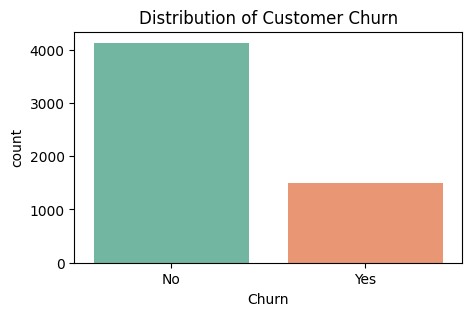

In [6]:
# Target distribution
plt.figure(figsize=(5, 3))
sns.countplot(x='Churn', data=train_df, palette='Set2')
plt.title('Distribution of Customer Churn')
plt.show()

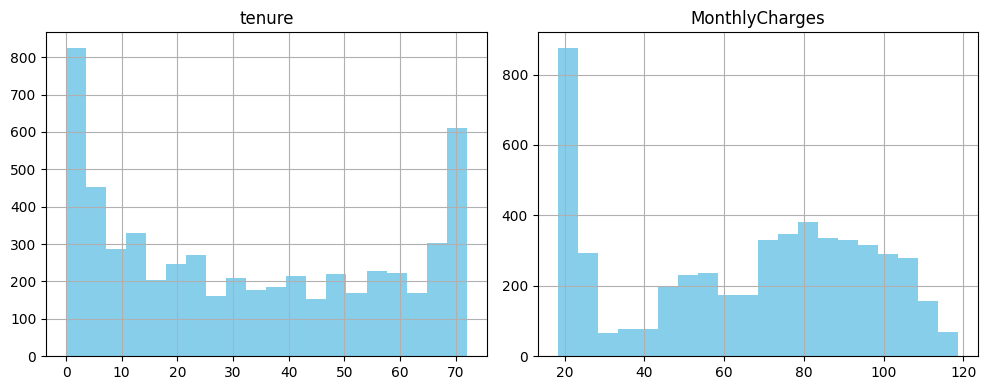

In [7]:
# Numerical feature distributions
train_df[['tenure', 'MonthlyCharges']].hist(bins=20, figsize=(10, 4), color='skyblue')
plt.tight_layout()
plt.show()

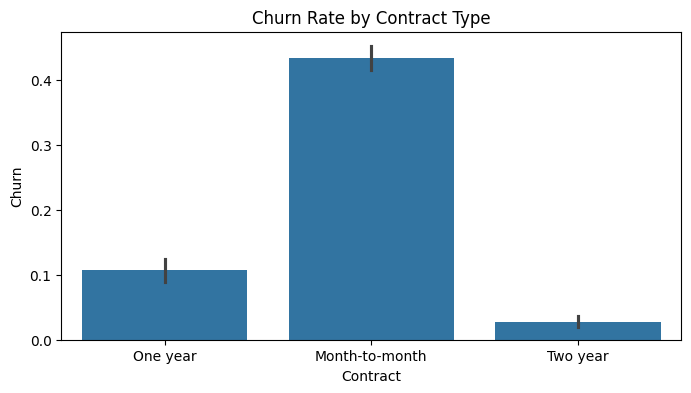

In [8]:
# Churn rate by Contract type
plt.figure(figsize=(8, 4))
sns.barplot(x='Contract', y='Churn', data=train_df.assign(Churn=(train_df['Churn']=='Yes').astype(int)))
plt.title('Churn Rate by Contract Type')
plt.show()

In [9]:
def preprocess_data(df):
    df = df.copy()

In [11]:
def preprocess_data(df, is_train=True, encoders=None):
    df = df.copy()

    # 1. Clean TotalCharges (convert to numeric, coercing errors to NaN)
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

    # 2. Handle missing values
    # Fill missing values in categorical columns with mode or a 'Unknown' placeholder
    df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
    df['OnlineSecurity'] = df['OnlineSecurity'].fillna('No')

    # Fill missing values in numerical columns with median
    df['MonthlyCharges'] = df['MonthlyCharges'].fillna(df['MonthlyCharges'].median())
    df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

    # Drop customerID as it is an identifier
    if 'customerID' in df.columns:
        df = df.drop(columns=['customerID'])

    # 3. Encode categorical features and target
    if is_train:
        encoders = {}
        for col in df.select_dtypes(include=['object']).columns:
            if col != 'Churn':
                le = LabelEncoder()
                df[col] = le.fit_transform(df[col].astype(str))
                encoders[col] = le
        if 'Churn' in df.columns:
            df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
        return df, encoders
    else:
        for col in df.select_dtypes(include=['object']).columns:
            if col in encoders:
                le = encoders[col]
                # Handle unseen categories by converting to string and mapping safely
                df[col] = df[col].astype(str).map(lambda s: s if s in le.classes_ else le.classes_[0])
                df[col] = le.transform(df[col])
        return df

# Run preprocessing
train_clean, encoders = preprocess_data(train_df, is_train=True)
test_clean = preprocess_data(test_df, is_train=False, encoders=encoders)

print("Preprocessed Training Data Shape:", train_clean.shape)
print("Preprocessed Testing Data Shape:", test_clean.shape)

Preprocessed Training Data Shape: (5634, 20)
Preprocessed Testing Data Shape: (1409, 20)


In [12]:
def feature_engineering(df):
    df = df.copy()

    # Customer Lifetime Value (Tenure * Monthly Charges)
    df['CLV'] = df['tenure'] * df['MonthlyCharges']

    # Drop unnecessary identifier
    if 'customerID' in df.columns:
        df = df.drop(columns=['customerID'])

    return df

train_df = feature_engineering(train_df)
test_df = feature_engineering(test_df)

# Separate target and features
if 'Churn' in train_df.columns:
    y = train_df['Churn'].map({'Yes': 1, 'No': 0})
    X = train_df.drop(columns=['Churn'])
else:
    X = train_df.copy()
    y = None

# One-Hot Encoding for categorical variables
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)

# Align test columns with train columns if needed
# (Ensure train and test have identical feature sets after dummy encoding)

In [14]:
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# 1. Feature Engineering on preprocessed datasets
def engineer_features(df):
    df = df.copy()
    df['CLV'] = df['tenure'] * df['MonthlyCharges']
    return df

train_engineered = engineer_features(train_clean)
test_engineered = engineer_features(test_clean)

# 2. Separate features and target
X = train_engineered.drop(columns=['Churn']) if 'Churn' in train_engineered.columns else train_engineered.copy()
y = train_engineered['Churn'] if 'Churn' in train_engineered.columns else None

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Scale numerical features
scaler = StandardScaler()
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'CLV']
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])

# 4. Initialize Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    proba = model.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, preds)
    prec = precision_score(y_val, preds)
    rec = recall_score(y_val, preds)
    f1 = f1_score(y_val, preds)
    roc = roc_auc_score(y_val, proba)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc
    })

results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
0  Logistic Regression  0.807453   0.656716  0.584718  0.618629  0.843214
1        Random Forest  0.799468   0.659574  0.514950  0.578358  0.835172
2    Gradient Boosting  0.811003   0.676000  0.561462  0.613430  0.848902


In [15]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation ROC-AUC:", grid_search.best_score_)

# Evaluate tuned model on validation set
best_model = grid_search.best_estimator_
tuned_preds = best_model.predict(X_val)
print("\nTuned Model Classification Report:\n")
print(classification_report(y_val, tuned_preds))

Best Hyperparameters: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 200}
Best Cross-Validation ROC-AUC: 0.8436109260298744

Tuned Model Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.90      0.88       826
           1       0.68      0.56      0.62       301

    accuracy                           0.81      1127
   macro avg       0.76      0.73      0.75      1127
weighted avg       0.80      0.81      0.81      1127

